**Human Movement Intelligence | Multimodal Movement Learning | Presented by: Reza Saadatyar (2026)**

**05 | Frozen Person-Independent Multimodal Evaluation**

![Frozen Person-Independent Multimodal Evaluation workflow](../../images/05_frozen_person_independent_test.svg)

**Research objective:** Quantify the difference between a Development-selected fusion model and the strongest Development-selected unimodal comparator on reserved previously unseen people.

**Dataset:** Source-aligned NinaPro DB2 E1 windows with saved participant roles, candidate metrics and the fixed selection from Notebook 04.

**Notebook scope:** Refit selected architectures on permitted Development data, then measure independent Test participant outcomes, fixed-class error patterns and computation cost.

**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/human-movement-intelligence


**01. Imports and Research Environment**

In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("multimodal_movement_learning")

# ---------------------------- 2. Standard Library ----------------------------
import shutil
import time

# ----------------- 3. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 4. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure
from core.output_download import download_outputs_from_colab

plot_style(
    font_family="DejaVu Sans", title_size=12.5, title_weight="normal",
    label_size=11.5, label_weight="normal", tick_size=11,
    legend_size=10, figure_dpi=100, figure_size=(9, 4),
)
# -------------------- 5. Deep Learning and Compute Device --------------------
from core.computer_device import computer_device
device = computer_device(min_vram_gb=None)

# ------------------------ 6. Study Research Utilities ------------------------
from ninapro_dataset import check_artifact_alignment, ensure_numerical_cache
from ninapro_evaluation import (
    build_classical, classical_features, aligned_probabilities,
    participant_metrics, predictions_from_probabilities,
    paired_subject_bootstrap,
)
from ninapro_models import UNIMODAL_MODELS, FUSION_MODELS
from ninapro_training import fit_neural, predict_neural, benchmark_cpu

# ---------------------- 7. Source and Output Locations -----------------------
study_dir = root / "multimodal_movement_learning"
output_dir = study_dir / "output"
processed_dir = root / "data" / "processed" / "ninapro_db2"
raw_dir = root / "data" / "raw" / "ninapro_db2"
output_dir.mkdir(parents=True, exist_ok=True)
processed_dir.mkdir(parents=True, exist_ok=True)
print("Research output directory:", output_dir)


Repository up to date.
Compute device and system information
OS: Linux 6.6.159+
CPU: x86_64
Installed RAM: 12.7 GiB
NVIDIA GPU: Tesla T4
Total VRAM: 15.00 GiB
PyTorch version: 2.14.1+cu130
CUDA device: Tesla T4
CUDA runtime: 13.0
cuDNN version: 92800
PyTorch total VRAM: 14.56 GiB
Selected compute device: cuda
Research output directory: /content/human-movement-intelligence/multimodal_movement_learning/output


**02. Read Frozen Development Selection Before Test Evaluation**

The two comparison recipes and any deep-late-fusion components are read from Notebook 04's completed Development selection table. No Test performance is consulted to select a model, epoch count, sensor subset or class definition. The class order remains the one established from source E1 labels.

In [3]:
# ======= 02. Read Frozen Development Selection Before Test Evaluation ========

NOTEBOOK_NUMBER = 5
SEED = 42
selection = pd.read_csv(output_dir / "04_model_selection.csv").fillna("")
if set(selection.selection_role) != {"unimodal_comparator", "fusion_comparator"}:
    raise ValueError("Exactly one selected unimodal and one selected fusion recipe are required.")
best_unimodal = str(selection.set_index("selection_role").loc["unimodal_comparator", "model_id"])
best_fusion = str(selection.set_index("selection_role").loc["fusion_comparator", "model_id"])
late_emg = str(selection.set_index("selection_role").loc["fusion_comparator", "component_emg"])
late_acc = str(selection.set_index("selection_role").loc["fusion_comparator", "component_acc"])
classes = np.sort(pd.read_csv(output_dir / "01_label_dictionary.csv").label.to_numpy(int))
train_evidence = pd.concat([
    pd.read_csv(output_dir / "03_dev_neural_metrics.csv"),
    pd.read_csv(output_dir / "04_dev_deep_fusion_metrics.csv"),
], ignore_index=True)
print("Frozen unimodal comparator:", best_unimodal)
print("Frozen fusion comparator:", best_fusion)
print("Source classes:", classes.tolist())


Frozen unimodal comparator: B1_rf
Frozen fusion comparator: F1_rf
Source classes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]


**03. Validate Independent Subject Roles and Input Contracts**

The five Test participants are entirely absent from Development fitting. The frozen classical comparators (`B1_rf` and `F1_rf`) use only the **48-column sEMG** and **96-column acceleration** feature matrices generated by Notebook 02. These matrices must retain the original 40,000 window-row order, correct shape and finite values. Loading them does not require the original 40 participants' time-series recordings. If a neural model is selected in a different Development run, the existing source-aligned temporal-cache recovery is used instead. In a fresh Colab session, mount the intended Google Drive account before this section if the two cached matrices are stored at `/content/drive/MyDrive/HMI/ninapro_db2/`; the loader then restores only these two files. Otherwise it raises a clear missing-feature error rather than downloading all 40 participants. Feature restoration must not change the fixed window index or participant roles.


In [4]:
# ======== 03. Validate Independent Subject Roles and Input Contracts =========

index = pd.read_csv(output_dir / "02_window_index.csv")
roles = pd.read_csv(output_dir / "02_participant_split_assignments.csv")
index["role"] = index.subject_id.map(dict(zip(roles.subject_id, roles.role)))
if index.role.isna().any():
    raise ValueError("A source participant has no frozen Development/Test role.")
development = index.loc[index.role == "Development"].copy()
test = index.loc[index.role == "Test"].copy()
if not len(development) or not len(test):
    raise ValueError("Both reserved Test and Development windows are required.")
if set(development.subject_id) & set(test.subject_id):
    raise ValueError("Participant overlap invalidates the independent Test comparison.")
# The Development-frozen choices are both classical Random Forest models.
# Avoid reconstructing the 40 subject recordings when only cached statistical
# features are needed; retain the original temporal path for neural choices.
classical_candidates = {
    "B0_prior", "B1_logreg", "B1_rf", "B2_logreg", "B2_rf",
    "F1_logreg", "F1_rf",
}
if {best_unimodal, best_fusion} <= classical_candidates:
    emg_path = processed_dir / "02_emg_features.npy"
    acc_path = processed_dir / "02_acc_features.npy"
    missing = [p.name for p in (emg_path, acc_path) if not p.is_file()]
    if missing:
        # Optional persistent cache: use only the two required matrices from
        # an already mounted Google Drive, without retrieving source recordings.
        drive_cache = Path("/content/drive/MyDrive/HMI/ninapro_db2")
        for path in (emg_path, acc_path):
            backup = drive_cache / path.name
            if not path.is_file() and backup.is_file():
                shutil.copy2(backup, path)
        missing = [p.name for p in (emg_path, acc_path) if not p.is_file()]
    if missing:
        raise FileNotFoundError(
            "Notebook 05's selected classical comparators need only two "
            "Notebook 02 feature matrices. Restore these files to "
            f"{processed_dir} before continuing: {missing}. "
            "No new feature extraction or raw-source download is required."
        )
    emg_features = np.load(emg_path, mmap_mode="r", allow_pickle=False)
    acc_features = np.load(acc_path, mmap_mode="r", allow_pickle=False)
    check_artifact_alignment(index, (emg_features, acc_features))
    if (
        emg_features.shape != (len(index), 48)
        or acc_features.shape != (len(index), 96)
        or not np.isfinite(emg_features).all()
        or not np.isfinite(acc_features).all()
    ):
        raise ValueError("Cached classical features violate Notebook 02's contract.")
    print("Reused paired statistical feature matrices (no raw-signal recovery).")
else:
    # A future neural fusion selection still needs the original temporal arrays.
    emg_features, acc_features = ensure_numerical_cache(
        root, index, allow_source_download=True, verbose=True,
    )
print("Development people:", development.subject_id.nunique())
print("Reserved Test people:", test.subject_id.nunique())
print("Test paired windows:", len(test))


Reused paired statistical feature matrices (no raw-signal recovery).
Development people: 35
Reserved Test people: 5
Test paired windows: 5000


**04. Define Final Fit Epochs from Development Only**

Neural final refits use the median best epoch observed in grouped Development training. The fixed epoch count is then applied to all Development people, without holding out Test people for stopping or changing settings based on Test outcomes.

In [5]:
# ============= 04. Define Final Fit Epochs from Development Only =============

def final_epochs(name):
    observed = train_evidence.loc[
        (train_evidence.model_id == name) &
        train_evidence.best_epochs.notna(), "best_epochs",
    ]
    if observed.empty:
        raise ValueError(f"Missing Development epoch-selection evidence for {name}")
    return max(1, int(np.rint(np.median(observed))))

for name in [best_unimodal, best_fusion, late_emg, late_acc]:
    if name in (*UNIMODAL_MODELS, *FUSION_MODELS):
        print(name, "frozen refit epochs:", final_epochs(name))


**05. Refit Selected Unimodal and Fusion Pipelines**

Classical estimators fit their scaling and classifier on Development features only. Neural networks fit Development-only channel normalisation and train all Development participants for a fixed number of epochs. Late fusion fits its two previously selected components independently, then combines their fixed-class probabilities with predetermined equal weights.

In [6]:
# ============= 05. Refit Selected Unimodal and Fusion Pipelines ==============

classical_names = {"B0_prior", "B1_logreg", "B1_rf", "B2_logreg", "B2_rf",
                   "F1_logreg", "F1_rf"}
trained = {}
fit_details = {}

def _fit_component(name):
    if name in trained:
        return
    start = time.perf_counter()
    if name in classical_names:
        model = build_classical(name, seed=SEED)
        features = classical_features(name,
            emg_features[development.window_row], acc_features[development.window_row])
        model.fit(features, development.label.to_numpy(int))
        import pickle
        details = {"fit_seconds": time.perf_counter() - start,
                   "model_size_bytes": len(pickle.dumps(model)),
                   "parameter_count": np.nan, "final_fit_epochs": np.nan}
        trained[name] = (model, None)
    elif name in (*UNIMODAL_MODELS, *FUSION_MODELS):
        model, stats, history, info = fit_neural(
            name, development, processed_dir, classes, device=device,
            seed=SEED, fixed_epochs=final_epochs(name),
        )
        details = {"fit_seconds": info["fit_seconds"],
                   "model_size_bytes": sum(p.nelement()*p.element_size()
                                           for p in model.parameters()),
                   "parameter_count": info["parameter_count"],
                   "final_fit_epochs": info["best_epochs"]}
        trained[name] = (model, stats)
    else:
        raise ValueError(f"Unsupported frozen component: {name}")
    fit_details[name] = details

if best_fusion.startswith("F2_"):
    suffix = best_fusion.split("_", 1)[1]
    late_components = (f"B1_{suffix}", f"B2_{suffix}")
elif best_fusion == "F4_deep_late":
    late_components = (late_emg, late_acc)
else:
    late_components = ()
for model_name in dict.fromkeys([best_unimodal, *late_components,
                                  *([] if late_components else [best_fusion])]):
    _fit_component(model_name)
print("Final fitted component models:", list(trained))


Final fitted component models: ['B1_rf', 'F1_rf']


**06. Generate Held-Out Test Probabilities and Measure Costs**

The two frozen comparisons receive the same Test windows in the same order. Inference latency is measured on CPU over a small fixed batch to avoid conflating GPU availability with model choice; source-array recovery and training are not included in this latency. Trained models are retained in memory only, not loaded from untrusted serialisations.

In [7]:
# ======== 06. Generate Held-Out Test Probabilities and Measure Costs =========

def _predict_component(name):
    model, stats = trained[name]
    if stats is None:
        p = aligned_probabilities(model, classical_features(name,
            emg_features[test.window_row], acc_features[test.window_row]), classes)
        sample = classical_features(name,
            emg_features[test.window_row.iloc[:min(64, len(test))]],
            acc_features[test.window_row.iloc[:min(64, len(test))]])
        for _ in range(2): model.predict_proba(sample)
        start = time.perf_counter()
        for _ in range(5): model.predict_proba(sample)
        latency = (time.perf_counter() - start) * 1000 / (5 * len(sample))
    else:
        p = predict_neural(name, model, test, processed_dir, classes,
                           stats, device=device)
        latency = benchmark_cpu(name, model, test, processed_dir, classes, stats)
    return p, float(latency)

probability_cache = {}
latency_cache = {}
for component in trained:
    probability_cache[component], latency_cache[component] = _predict_component(component)

def _selected_probability(name):
    if name == best_fusion and late_components:
        return 0.5 * (probability_cache[late_components[0]] +
                      probability_cache[late_components[1]])
    return probability_cache[name]

comparison = {
    "unimodal_comparator": best_unimodal,
    "fusion_comparator": best_fusion,
}
comparison_probabilities = {role: _selected_probability(name)
                            for role, name in comparison.items()}
for role, proba in comparison_probabilities.items():
    if proba.shape != (len(test), len(classes)) or not np.allclose(proba.sum(axis=1), 1, atol=1e-4):
        raise ValueError(f"Invalid final fixed-class probabilities: {role}")
print("Matched Test predictions constructed for both frozen comparators.")


Matched Test predictions constructed for both frozen comparators.


**07. Score Fixed-Class Outcomes at the Participant Level**

Calculate fixed-class macro F1 and balanced accuracy independently for each reserved Test participant, giving each person equal weight in the primary estimate. Save source-keyed Test predictions and probabilities for the two frozen recipes. Report all 18 corrected E1 classes under the established unsupported-class convention; do not use Test observations for model selection.


In [8]:
# ========== 07. Score Fixed-Class Outcomes at the Participant Level ==========

metric_frames, prediction_frames, cost_rows = [], [], []
for role, model_name in comparison.items():
    proba = comparison_probabilities[role]
    score = participant_metrics(test.reset_index(drop=True), proba,
                                classes, model_id=model_name, seed=SEED)
    score["comparison_role"] = role
    metric_frames.append(score)
    frame = test[["window_key", "subject_id", "segment_id", "repetition_id",
                  "start_s", "end_s", "label"]].copy().reset_index(drop=True)
    frame["model_id"] = model_name
    frame["comparison_role"] = role
    frame["predicted_label"] = predictions_from_probabilities(proba, classes)
    for j, source_class in enumerate(classes):
        frame[f"p_class_{int(source_class)}"] = proba[:, j]
    prediction_frames.append(frame)
    components = late_components if (role == "fusion_comparator" and late_components) else (model_name,)
    cost_rows.append({
        "comparison_role": role, "model_id": model_name,
        "fit_seconds": sum(fit_details[c]["fit_seconds"] for c in components),
        "model_size_bytes": sum(fit_details[c]["model_size_bytes"] for c in components),
        "parameter_count": (
            float(sum(fit_details[c]["parameter_count"] for c in components))
            if all(np.isfinite(fit_details[c]["parameter_count"])
                   for c in components)
            else np.nan
        ),
        "cpu_ms_per_window": sum(latency_cache[c] for c in components),
    })
test_metrics = pd.concat(metric_frames, ignore_index=True)
test_predictions = pd.concat(prediction_frames, ignore_index=True)
test_metrics.to_csv(output_dir / "05_test_metrics.csv", index=False)
test_predictions.to_csv(output_dir / "05_test_predictions.csv", index=False)
costs = pd.DataFrame(cost_rows)
costs.to_csv(output_dir / "05_model_costs.csv", index=False)
display(test_metrics.groupby("comparison_role", as_index=False).agg(
    participant_mean_macro_f1=("macro_f1", "mean"),
    participant_mean_balanced_accuracy=("fixed_class_balanced_accuracy", "mean"),
    independent_people=("subject_id", "nunique")))


,comparison_role,participant_mean_macro_f1,participant_mean_balanced_accuracy,independent_people
0,fusion_comparator,0.312600,0.350991,5
1,unimodal_comparator,0.251178,0.287890,5


**08. Quantify Paired Participant Differences and Uncertainty**

The paired difference is fusion minus the prespecified unimodal comparator for each held-out person. The participant-level bootstrap resamples people rather than correlated overlapping windows. With a small number of Test participants, its interval is descriptive and conditional on the fitted models; it cannot establish population-wide superiority.

In [9]:
# ======== 08. Quantify Paired Participant Differences and Uncertainty ========

wide = test_metrics.pivot(index="subject_id", columns="comparison_role",
                          values="macro_f1")
wide["fusion_minus_unimodal"] = (wide["fusion_comparator"] -
                                 wide["unimodal_comparator"])
uncertainty = paired_subject_bootstrap(wide.fusion_minus_unimodal.to_numpy(), seed=SEED)
summary = pd.DataFrame([{
    "fusion_model": best_fusion, "unimodal_model": best_unimodal,
    "fusion_mean_subject_macro_f1": float(wide.fusion_comparator.mean()),
    "unimodal_mean_subject_macro_f1": float(wide.unimodal_comparator.mean()),
    **uncertainty,
}])
summary.to_csv(output_dir / "05_test_summary.csv", index=False)
wide.reset_index().to_csv(output_dir / "05_subject_differences.csv", index=False)
display(summary.T.rename(columns={0: "observed estimate"}))


,observed estimate
fusion_model,F1_rf
unimodal_model,B1_rf
fusion_mean_subject_macro_f1,0.3126
unimodal_mean_subject_macro_f1,0.251178
mean_difference,0.061423
bootstrap_2_5pct,0.033337
bootstrap_97_5pct,0.080434
independent_test_people,5
bootstrap_draws,2000


**09. Interpret Per-Class Errors and Runtime Trade-Offs**

Report **pooled-window per-class precision, recall, F1, true support and predicted-window counts** for both frozen models. These class-specific scores complement rather than replace the primary equal-participant macro F1. Display both the count-based and true-class-row-normalised fusion confusion matrices, paired Test participant differences and measured CPU inference latency. Interpretation remains descriptive for the five previously unseen participants; synthetic or clinical generalisation is not implied.


,comparison_role,model_id,label,support,predicted_windows,precision,recall,f1
0,unimodal_comparator,B1_rf,0,2691,2387,0.850021,0.753995,0.799134
1,unimodal_comparator,B1_rf,1,212,179,0.145251,0.122642,0.132992
2,unimodal_comparator,B1_rf,2,159,234,0.042735,0.062893,0.050891
3,unimodal_comparator,B1_rf,3,144,157,0.203822,0.222222,0.212625
4,unimodal_comparator,B1_rf,4,129,122,0.065574,0.062016,0.063745
5,unimodal_comparator,B1_rf,5,103,78,0.166667,0.126214,0.143646
6,unimodal_comparator,B1_rf,6,99,104,0.432692,0.454545,0.443350
7,unimodal_comparator,B1_rf,7,175,108,0.037037,0.022857,0.028269
8,unimodal_comparator,B1_rf,8,131,56,0.017857,0.007634,0.010695
9,unimodal_comparator,B1_rf,9,149,333,0.246246,0.550336,0.340249


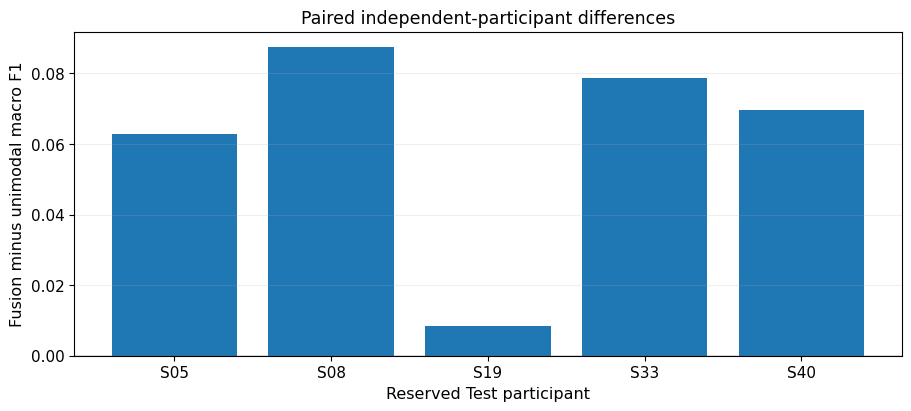

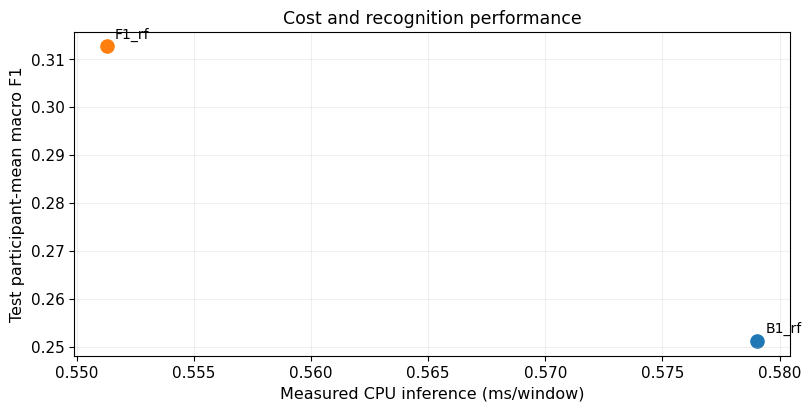

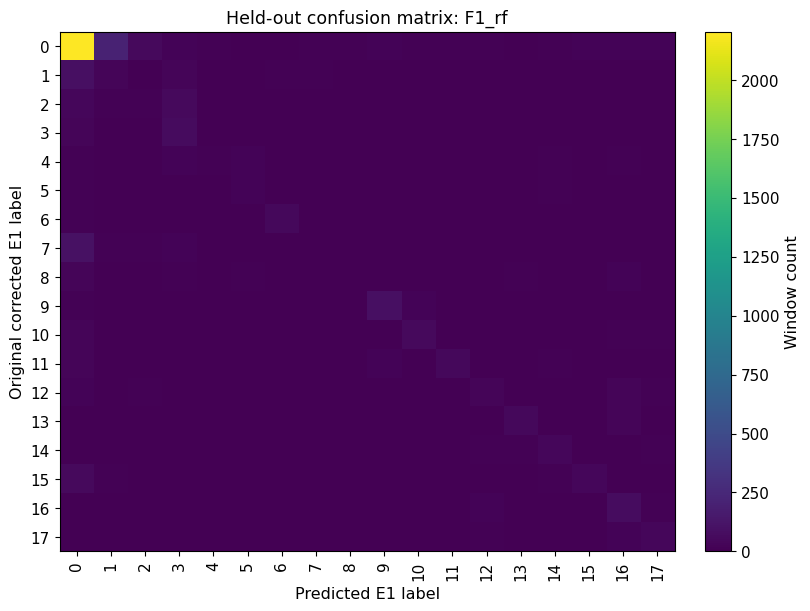

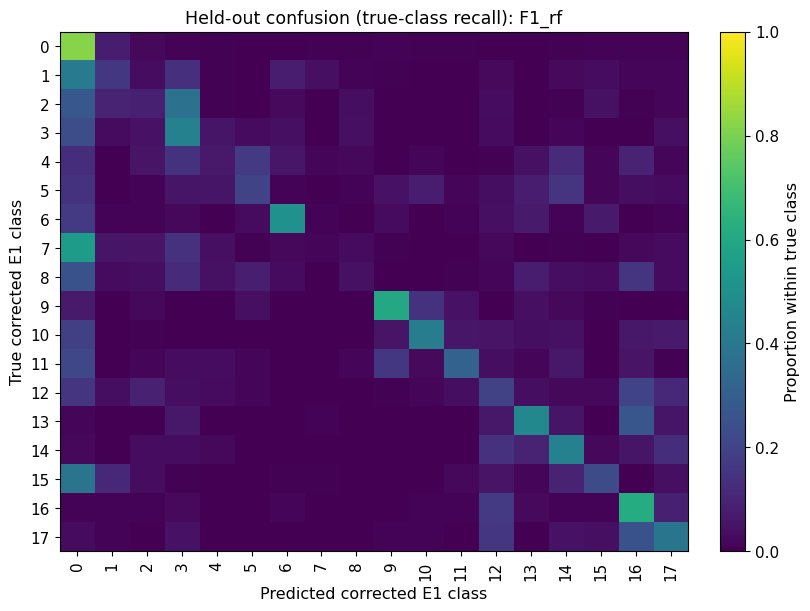

In [10]:
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

per_class_rows = []
for role, model_name in comparison.items():
    pred = predictions_from_probabilities(
        comparison_probabilities[role], classes,
    )
    precision, recall, class_f1, support = precision_recall_fscore_support(
        test.label.to_numpy(int), pred, labels=classes, zero_division=0,
    )
    predicted_windows = np.bincount(
        np.searchsorted(classes, pred), minlength=len(classes),
    )
    for i, label in enumerate(classes):
        per_class_rows.append({
            "comparison_role": role,
            "model_id": model_name,
            "label": int(label),
            "support": int(support[i]),
            "predicted_windows": int(predicted_windows[i]),
            "precision": float(precision[i]),
            "recall": float(recall[i]),
            "f1": float(class_f1[i]),
        })
per_class = pd.DataFrame(per_class_rows)
per_class.to_csv(output_dir / "05_per_class_support.csv", index=False)
display(per_class)

fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
ax.bar(wide.index, wide.fusion_minus_unimodal)
ax.axhline(0, color="0.4", lw=1)
ax.set(xlabel="Reserved Test participant", ylabel="Fusion minus unimodal macro F1",
       title="Paired independent-participant differences")
ax.grid(axis="y", alpha=.2)
save_figure(fig, output_dir / "05_subject_differences.png")
plt.show()

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
for row in costs.itertuples(index=False):
    score = test_metrics.loc[test_metrics.comparison_role == row.comparison_role, "macro_f1"].mean()
    ax.scatter(row.cpu_ms_per_window, score, s=90)
    ax.annotate(row.model_id, (row.cpu_ms_per_window, score), xytext=(6, 6),
                textcoords="offset points")
ax.set(xlabel="Measured CPU inference (ms/window)", ylabel="Test participant-mean macro F1",
       title="Cost and recognition performance")
ax.grid(alpha=.2)
save_figure(fig, output_dir / "05_cost_accuracy.png")
plt.show()

pred = predictions_from_probabilities(comparison_probabilities["fusion_comparator"], classes)
cm = confusion_matrix(test.label.to_numpy(int), pred, labels=classes)
fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")
im = ax.imshow(cm, aspect="auto")
ax.set(xlabel="Predicted E1 label", ylabel="Original corrected E1 label",
       title=f"Held-out confusion matrix: {best_fusion}")
ax.set_xticks(np.arange(len(classes)), labels=classes, rotation=90)
ax.set_yticks(np.arange(len(classes)), labels=classes)
fig.colorbar(im, ax=ax, label="Window count")
save_figure(fig, output_dir / "05_confusion_matrix.png")
plt.show()

# Row-normalised confusion gives each source class a comparable visual scale.
# Unsupported true classes (if any) have zero-valued rows by convention.
class_support = cm.sum(axis=1, keepdims=True)
cm_normalised = np.divide(
    cm, class_support, out=np.zeros_like(cm, dtype=float),
    where=class_support > 0,
)
fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")
im = ax.imshow(cm_normalised, aspect="auto", vmin=0, vmax=1)
ax.set(
    xlabel="Predicted corrected E1 class",
    ylabel="True corrected E1 class",
    title=f"Held-out confusion (true-class recall): {best_fusion}",
)
ax.set_xticks(np.arange(len(classes)), labels=classes, rotation=90)
ax.set_yticks(np.arange(len(classes)), labels=classes)
fig.colorbar(im, ax=ax, label="Proportion within true class")
save_figure(fig, output_dir / "05_confusion_matrix_normalised.png")
plt.show()



**10. Current Outputs and Scientific Interpretation**

The final Test outputs contain the frozen predictions and per-participant metrics, pooled per-class precision/recall/F1, paired participant differences with a participant-level bootstrap interval, fitted-model cost summaries, count and true-class-normalised confusion matrices, and comparison figures. Results must be interpreted as **offline, within-NinaPro DB2 person-independent recognition** only. The five-person uncertainty estimate is descriptive and does not validate online prosthetic use, clinical deployment or generalisation to new acquisition devices. No Test score is stated here before this notebook is executed.


In [11]:
# ============= 10. Current Outputs and Scientific Interpretation =============

display(pd.DataFrame({"output_file": [
    p.name for p in sorted(output_dir.glob("%02d_*" % NOTEBOOK_NUMBER))
    if p.is_file()
]}))
download_outputs_from_colab(
    folder="multimodal_movement_learning/output",
    stage=f"{NOTEBOOK_NUMBER:02d}",
)


,output_file
0,05_confusion_matrix.png
1,05_confusion_matrix_normalised.png
2,05_cost_accuracy.png
3,05_model_costs.csv
4,05_per_class_support.csv
5,05_subject_differences.csv
6,05_subject_differences.png
7,05_test_metrics.csv
8,05_test_predictions.csv
9,05_test_summary.csv


------------------------------------------------------------------------
Notebook 05
Files packaged: 10
  + 05_confusion_matrix.png
  + 05_confusion_matrix_normalised.png
  + 05_cost_accuracy.png
  + 05_model_costs.csv
  + 05_per_class_support.csv
  + 05_subject_differences.csv
  + 05_subject_differences.png
  + 05_test_metrics.csv
  + 05_test_predictions.csv
  + 05_test_summary.csv
Download ZIP from Colab Contents: /content/multimodal_movement_learning_Notebook_05_Outputs.zip
